# Module 20 — Required Try-It 20.1: Comparing Aggregating Models for Regression

**Objective:** Predict hourly wages using the OpenML census dataset (ID 534), compare five individual regressors against a tuned `VotingRegressor`, and interpret wage predictors.  
**Important:** Results are generated only when this notebook runs; no performance values are assumed in advance.

Run from the project root or the `notebooks/` folder. Requires internet on first run to retrieve OpenML data. The data and outputs are generated locally.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, KFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.ensemble import VotingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

RANDOM_STATE = 42
cwd = Path.cwd()
project_root = cwd.parent if cwd.name == 'notebooks' else cwd
figures_dir = project_root / 'outputs' / 'figures'
reports_dir = project_root / 'outputs' / 'reports'
figures_dir.mkdir(parents=True, exist_ok=True)
reports_dir.mkdir(parents=True, exist_ok=True)
print('Project root:', project_root.resolve())

Project root: /Users/aravat/Documents/Python/Working/Module_20/Assignment_20


## 1. Load and inspect the wage dataset

In [2]:
from sklearn.datasets import fetch_openml
import pandas as pd

# Load the wage dataset
survey = fetch_openml(data_id=534, as_frame=True).frame.copy()

# Standardize column names to lowercase
survey.columns = survey.columns.str.strip().str.lower()

print("Dataset shape:", survey.shape)
print("Columns:", survey.columns.tolist())

display(survey.head())

# Prepare target variable
survey["wage"] = pd.to_numeric(
    survey["wage"],
    errors="coerce"
)

# Remove observations without a valid wage
survey = survey.dropna(subset=["wage"]).copy()

# Separate predictors and target
X = survey.drop(columns=["wage"])
y = survey["wage"]

print("\nTarget variable: wage")
print("Number of observations:", len(survey))
print("Number of predictors:", X.shape[1])

print("\nWage statistics:")
display(y.describe())

print("\nMissing feature values:", int(X.isna().sum().sum()))

Dataset shape: (534, 11)
Columns: ['education', 'south', 'sex', 'experience', 'union', 'wage', 'age', 'race', 'occupation', 'sector', 'marr']


,education,south,sex,experience,union,wage,age,race,occupation,sector,marr
0,8,no,female,21,not_member,5.10,35,Hispanic,Other,Manufacturing,Married
1,9,no,female,42,not_member,4.95,57,White,Other,Manufacturing,Married
2,12,no,male,1,not_member,6.67,19,White,Other,Manufacturing,Unmarried
3,12,no,male,4,not_member,4.00,22,White,Other,Other,Unmarried
4,12,no,male,17,not_member,7.50,35,White,Other,Other,Married



Target variable: wage
Number of observations: 534
Number of predictors: 10

Wage statistics:


count    534.000000
mean       9.024064
std        5.139097
min        1.000000
25%        5.250000
50%        7.780000
75%       11.250000
max       44.500000
Name: wage, dtype: float64


Missing feature values: 0


## 2. Preprocessing and holdout split

Categorical features are one-hot encoded, numeric features are imputed and standardized. Preprocessing is fitted only on training data inside each pipeline to prevent leakage.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
num_cols = X_train.select_dtypes(include='number').columns.tolist()
cat_cols = X_train.columns.difference(num_cols).tolist()
num_pipe = Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())])
cat_pipe = Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                     ('onehot', OneHotEncoder(handle_unknown='ignore'))])
preprocess = ColumnTransformer([('num', num_pipe, num_cols), ('cat', cat_pipe, cat_cols)])
print('Numeric columns:', num_cols)
print('Categorical columns:', cat_cols)
print('Train / test rows:', len(X_train), len(X_test))

Numeric columns: ['education', 'experience', 'age']
Categorical columns: ['marr', 'occupation', 'race', 'sector', 'sex', 'south', 'union']
Train / test rows: 427 107


## 3. Five individual regression models and the voting ensemble

In [4]:
def make_model(regressor):
    return Pipeline([('preprocess', preprocess), ('regressor', regressor)])

base_estimators = [
    ('linear', LinearRegression()),
    ('knn', KNeighborsRegressor(n_neighbors=15)),
    ('tree', DecisionTreeRegressor(max_depth=8, min_samples_leaf=10, random_state=RANDOM_STATE)),
    ('ridge', Ridge(alpha=10.0)),
    ('svr', SVR(C=5.0, epsilon=0.1)),
]
models = {name: make_model(est) for name, est in base_estimators}
models['voting_equal'] = VotingRegressor(estimators=[(name, make_model(est)) for name, est in base_estimators])

# Train and evaluate on a held-out test set.
rows = []
fitted_models = {}
for name, model in models.items():
    print('Fitting:', name)
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    rows.append({'Model': name, 'RMSE': np.sqrt(mean_squared_error(y_test, preds)),
                 'MAE': mean_absolute_error(y_test, preds), 'R2': r2_score(y_test, preds)})
    fitted_models[name] = model
baseline_results = pd.DataFrame(rows).sort_values('RMSE').reset_index(drop=True)
display(baseline_results.round(4))

Fitting: linear
Fitting: knn
Fitting: tree
Fitting: ridge
Fitting: svr
Fitting: voting_equal


,Model,RMSE,MAE,R2
0,svr,4.3604,2.9226,0.4036
1,voting_equal,4.3880,3.1019,0.3960
2,linear,4.4162,3.2132,0.3882
3,ridge,4.4361,3.2498,0.3827
4,knn,4.4753,3.2129,0.3717
5,tree,4.9460,3.5370,0.2326


## 4. Tune the VotingRegressor on training data only

Tune ensemble weights and selected base-model parameters using cross-validation. **Do not tune against the test set.**

In [5]:
cv = KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
param_distributions = {
    'weights': [(1,1,1,1,1), (2,1,1,2,1), (3,1,1,3,1), (1,2,1,2,1), (2,1,2,2,1)],
    'linear__regressor__fit_intercept': [True, False],
    'knn__regressor__n_neighbors': [5, 10, 15, 25],
    'tree__regressor__max_depth': [5, 8, 12],
    'ridge__regressor__alpha': [0.1, 1.0, 10.0, 100.0],
    'svr__regressor__C': [1.0, 5.0, 10.0],
}
search = RandomizedSearchCV(
    estimator=VotingRegressor(estimators=[(name, make_model(est)) for name, est in base_estimators]),
    param_distributions=param_distributions,
    n_iter=12, scoring='neg_root_mean_squared_error', cv=cv,
    random_state=RANDOM_STATE, n_jobs=-1, verbose=1,
)
search.fit(X_train, y_train)
tuned = search.best_estimator_
preds_tuned = tuned.predict(X_test)
tuned_row = {'Model': 'voting_tuned',
             'RMSE': np.sqrt(mean_squared_error(y_test, preds_tuned)),
             'MAE': mean_absolute_error(y_test, preds_tuned),
             'R2': r2_score(y_test, preds_tuned)}
results = pd.concat([baseline_results, pd.DataFrame([tuned_row])], ignore_index=True).sort_values('RMSE').reset_index(drop=True)
print('Best CV RMSE (training folds):', -search.best_score_)
print('Best parameters:', search.best_params_)
display(results.round(4))

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best CV RMSE (training folds): 4.399434504011916
Best parameters: {'weights': (2, 1, 1, 2, 1), 'tree__regressor__max_depth': 5, 'svr__regressor__C': 1.0, 'ridge__regressor__alpha': 1.0, 'linear__regressor__fit_intercept': True, 'knn__regressor__n_neighbors': 25}


,Model,RMSE,MAE,R2
0,svr,4.3604,2.9226,0.4036
1,voting_equal,4.3880,3.1019,0.3960
2,linear,4.4162,3.2132,0.3882
3,voting_tuned,4.4250,3.2059,0.3858
4,ridge,4.4361,3.2498,0.3827
5,knn,4.4753,3.2129,0.3717
6,tree,4.9460,3.5370,0.2326


## 5. Does the wisdom of the crowd win?

Best individual: svr RMSE: 4.3604
Best ensemble: voting_equal RMSE: 4.388
Ensemble outperforms best individual on holdout: False


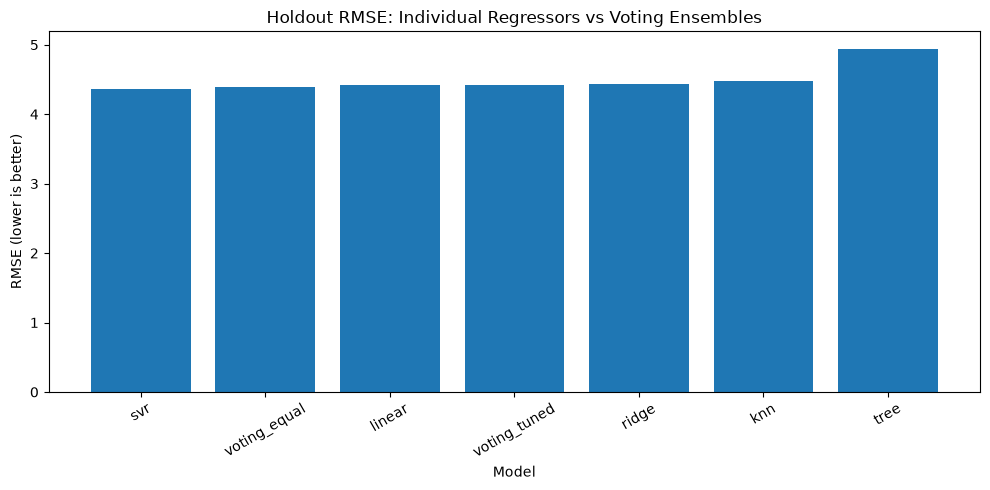

In [6]:
individual = results[results['Model'].isin(models.keys() - {'voting_equal'})]
best_individual = individual.loc[individual['RMSE'].idxmin()]
best_voting = results[results['Model'].isin(['voting_equal', 'voting_tuned'])].sort_values('RMSE').iloc[0]
print('Best individual:', best_individual['Model'], 'RMSE:', round(best_individual['RMSE'], 4))
print('Best ensemble:', best_voting['Model'], 'RMSE:', round(best_voting['RMSE'], 4))
print('Ensemble outperforms best individual on holdout:', bool(best_voting['RMSE'] < best_individual['RMSE']))
results.to_csv(reports_dir/'model_comparison.csv', index=False)
pd.DataFrame(search.cv_results_).to_csv(reports_dir/'voting_tuning_cv_results.csv', index=False)
fig, ax = plt.subplots(figsize=(10,5))
ax.bar(results['Model'], results['RMSE'])
ax.set(title='Holdout RMSE: Individual Regressors vs Voting Ensembles', xlabel='Model', ylabel='RMSE (lower is better)')
ax.tick_params(axis='x', rotation=30)
fig.tight_layout()
fig.savefig(figures_dir/'model_comparison.png', dpi=200, bbox_inches='tight')
plt.show()

## 6. Feature interpretability via permutation importance

`VotingRegressor` does not have a single coefficient or feature-importance vector. Permutation importance measures how much predictive error worsens when each original feature is shuffled on the held-out set. This is a model-agnostic measure of **predictive reliance**, not causation.

,Feature,RMSE increase,Std
0,education,1.0828,0.1395
7,occupation,0.4282,0.0571
3,experience,0.4006,0.1522
2,sex,0.2070,0.0895
5,age,0.1068,0.0683
8,sector,0.0130,0.0136
6,race,0.0108,0.0168
9,marr,-0.0075,0.0092
1,south,-0.0104,0.0380
4,union,-0.0365,0.0837


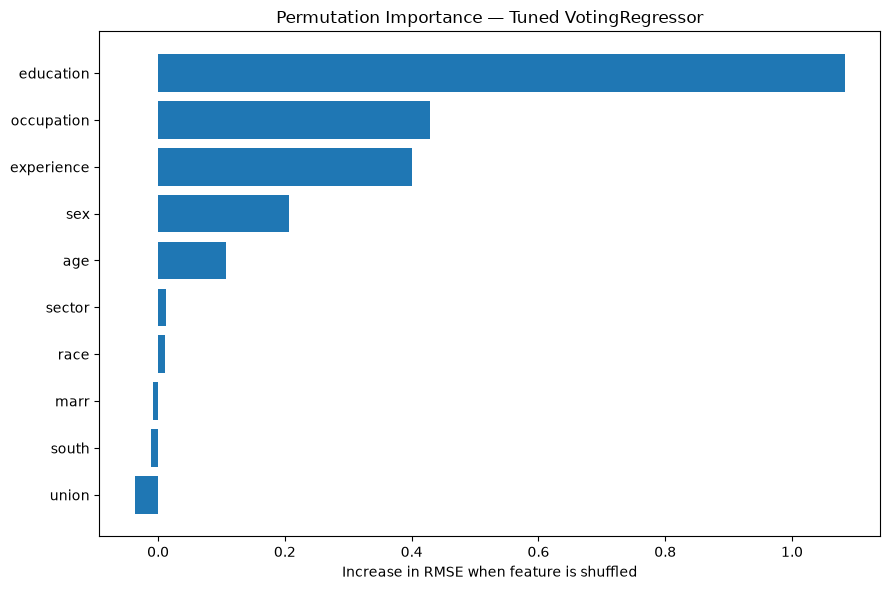

In [7]:
perm = permutation_importance(
    tuned, X_test, y_test, scoring='neg_root_mean_squared_error',
    n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1
)
importance = pd.DataFrame({'Feature': X_test.columns,
                           'RMSE increase': perm.importances_mean,
                           'Std': perm.importances_std}).sort_values('RMSE increase', ascending=False)
importance.to_csv(reports_dir/'permutation_feature_importance.csv', index=False)
display(importance.head(15).round(4))
top = importance.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(9,6))
ax.barh(top['Feature'], top['RMSE increase'])
ax.set(title='Permutation Importance — Tuned VotingRegressor', xlabel='Increase in RMSE when feature is shuffled')
fig.tight_layout()
fig.savefig(figures_dir/'feature_importance.png', dpi=200, bbox_inches='tight')
plt.show()

## 7. Export a discussion draft and verify outputs

In [8]:
winner = results.iloc[0]
feature_names = ', '.join(importance.head(3)['Feature'].astype(str))
text = f"""I used the OpenML census wage dataset (ID 534) to predict hourly wages. I compared Linear Regression, KNN, Decision Tree, Ridge, and SVR against both equal-weight and tuned VotingRegressor ensembles. I used a held-out test set and tuned the voting model with cross-validation on training data.

The lowest test RMSE was achieved by {winner['Model']} (RMSE={winner['RMSE']:.4f}). The best individual model was {best_individual['Model']} (RMSE={best_individual['RMSE']:.4f}), while the best ensemble was {best_voting['Model']} (RMSE={best_voting['RMSE']:.4f}). Thus, the ensemble {'outperformed' if best_voting['RMSE'] < best_individual['RMSE'] else 'did not outperform'} the best individual model on the held-out data.

Voting improves flexibility by combining different prediction methods, but its aggregate predictions are less directly interpretable than a linear model. I used permutation importance to examine which original input features influenced predictions most; the top three were {feature_names}. These are predictive associations, not causal effects."""
(reports_dir/'discussion_post.txt').write_text(text, encoding='utf-8')
print(text)
print('Word count:', len(text.split()))
for path in sorted((project_root/'outputs').rglob('*')):
    if path.is_file(): print(path.relative_to(project_root))

I used the OpenML census wage dataset (ID 534) to predict hourly wages. I compared Linear Regression, KNN, Decision Tree, Ridge, and SVR against both equal-weight and tuned VotingRegressor ensembles. I used a held-out test set and tuned the voting model with cross-validation on training data.

The lowest test RMSE was achieved by svr (RMSE=4.3604). The best individual model was svr (RMSE=4.3604), while the best ensemble was voting_equal (RMSE=4.3880). Thus, the ensemble did not outperform the best individual model on the held-out data.

Voting improves flexibility by combining different prediction methods, but its aggregate predictions are less directly interpretable than a linear model. I used permutation importance to examine which original input features influenced predictions most; the top three were education, occupation, experience. These are predictive associations, not causal effects.
Word count: 130
outputs/.DS_Store
outputs/figures/feature_importance.png
outputs/figures/model